In [4]:
%run ../notebooks/Preprocessing/Preprocessing.ipynb

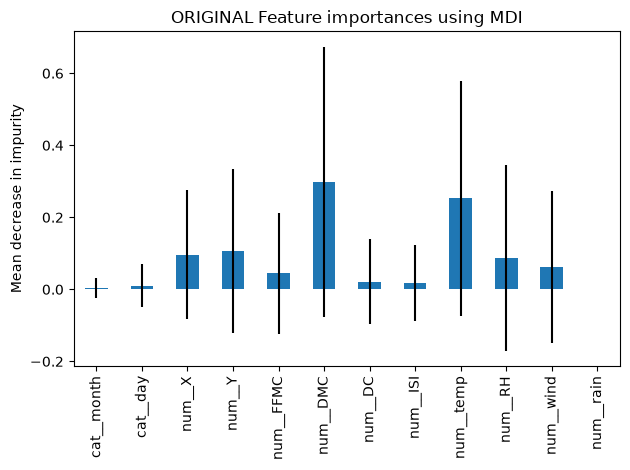

AttributeError: Estimator functiontransformer-1 does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import time

#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

forest = RandomForestRegressor(max_depth=20, random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    model = make_pipeline(preprocessing, forest)
    model.fit(X_train, y_train)
    
    start_time = time.time()
    importances = forest.feature_importances_
    std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
    elapsed_time = time.time() - start_time

    forest_importances = pd.Series(importances, index=model[:-1].get_feature_names_out())
    
    fig, ax = plt.subplots()
    forest_importances.plot.bar(yerr=std, ax=ax)
    ax.set_title(title + " Feature importances using MDI")
    ax.set_ylabel("Mean decrease in impurity")
    fig.tight_layout()
    plt.show()